# 03 · Ablation study (Task 3)

Model A (market only) vs Model B (market + Task 2 NLP) vs Model C (market + advanced text features), plus text-only, attention and late-fusion rows. All rows use the same protocol: expanding-window CV on train+val (600 out-of-fold days), parameters chosen by OOF ROC-AUC, final refit on train+val, a single evaluation on the 176 test days, 95% block-bootstrap CIs and a paired bootstrap against Model A. Produced by `python -m src.run_ablation`.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebook' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
FIG = 'report/figures/'
from src.analysis import ablation as ab

## Best model family per row (selected on OOF AUC only)

In [2]:
best = ab.best_per_set()
cols = ['label','model','oof_roc_auc','oof_d_roc_auc_vs_A','test_roc_auc','test_roc_auc_lo','test_roc_auc_hi','test_mcc','test_d_roc_auc_vs_A','test_d_roc_auc_lo','test_d_roc_auc_hi']
best[cols].round(3)

,label,model,oof_roc_auc,oof_d_roc_auc_vs_A,test_roc_auc,test_roc_auc_lo,test_roc_auc_hi,test_mcc,test_d_roc_auc_vs_A,test_d_roc_auc_lo,test_d_roc_auc_hi
0,A: market only,logreg,0.526,NaN,0.564,0.484,0.641,0.086,NaN,NaN,NaN
1,B: market + Task 2 NLP,logreg,0.515,-0.011,0.530,0.449,0.605,-0.003,-0.034,-0.111,0.034
2,C: Word2Vec (static),logreg,0.501,-0.025,0.521,0.433,0.606,-0.007,-0.044,-0.111,0.025
3,C: FastText (static),logreg,0.494,-0.032,0.537,0.452,0.623,0.054,-0.027,-0.079,0.029
4,C: IndoBERT (general),lightgbm,0.514,-0.005,0.515,0.430,0.599,0.074,-0.005,-0.090,0.077
5,C: IndoBERT-DAPT (domain),logreg,0.520,-0.006,0.536,0.455,0.621,0.027,-0.028,-0.093,0.039
6,C: multilingual-e5,logreg,0.489,-0.037,0.603,0.518,0.680,0.154,0.039,-0.029,0.107
7,C: transformer sentiment,lightgbm,0.549,0.030,0.538,0.455,0.625,0.045,0.018,-0.040,0.074
8,"C: e5, recency-weighted",lightgbm,0.530,0.011,0.566,0.474,0.655,0.157,0.047,-0.065,0.155
9,"C: e5, decay (h=3 days)",xgboost,0.512,-0.008,0.560,0.488,0.631,0.105,0.033,-0.052,0.121


## Task 2 vs Task 3

Task 2 numbers come from its single-validation-split protocol (`results/task2/`); Task 3 numbers from the CV protocol.

In [3]:
ab.task2_vs_task3().round(3)

,variant,protocol,test_auc,test_mcc,test_acc,test_f1,oof_auc
0,Task 2 A (logreg),Task 2,0.569,0.034,0.523,0.515,NaN
1,Task 2 A (xgboost),Task 2,0.533,0.177,0.625,0.507,NaN
2,Task 2 B (logreg),Task 2,0.504,-0.006,0.489,0.488,NaN
3,Task 2 B (xgboost),Task 2,0.579,0.101,0.602,0.478,NaN
4,A: market only (logreg),Task 3,0.564,0.086,0.551,0.542,0.526
5,B: market + Task 2 NLP (logreg),Task 3,0.530,-0.003,0.483,0.483,0.515
6,C: Word2Vec (static) (logreg),Task 3,0.521,-0.007,0.506,0.496,0.501
7,C: FastText (static) (logreg),Task 3,0.537,0.054,0.540,0.527,0.494
8,C: IndoBERT (general) (lightgbm),Task 3,0.515,0.074,0.534,0.531,0.514
9,C: IndoBERT-DAPT (domain) (logreg),Task 3,0.536,0.027,0.528,0.513,0.520


## Difference to Model A with 95% paired-bootstrap CIs

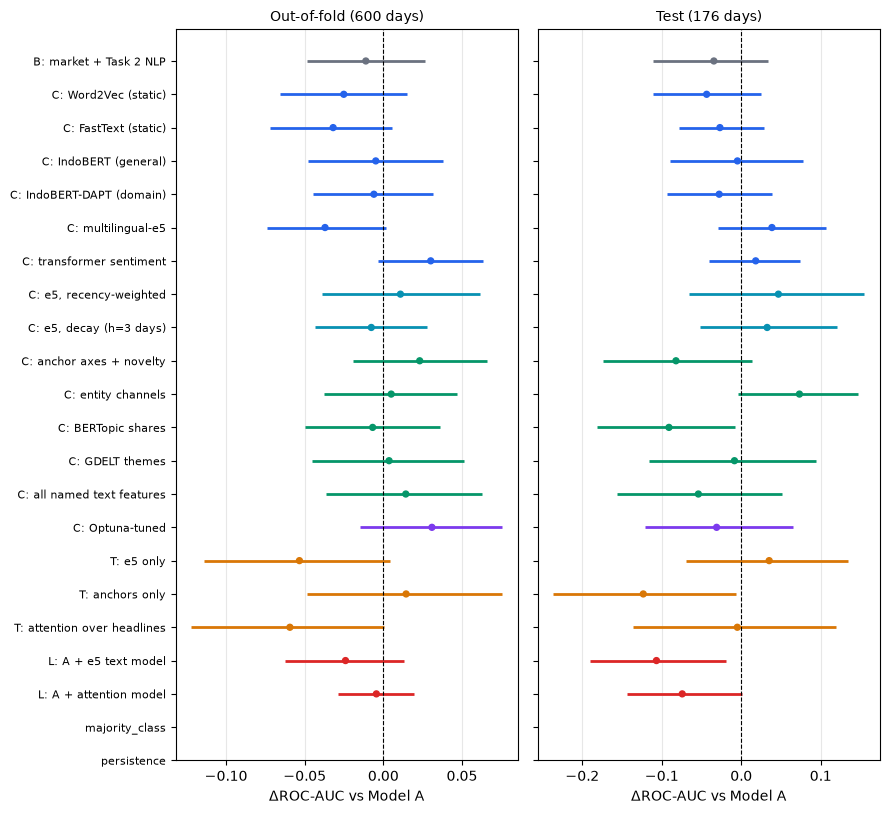

In [4]:
fig = ab.forest_plot(FIG + 'ablation_forest.pdf')

## Stability across the five CV blocks

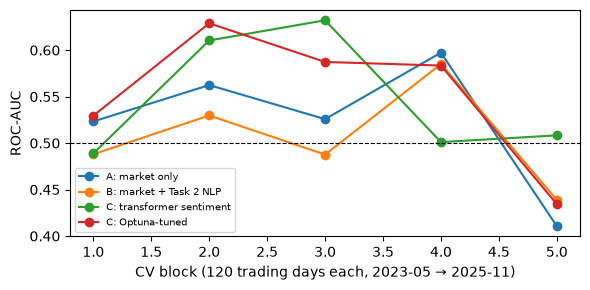

In [5]:
fig = ab.fold_stability(('A', 'B', best.loc[best['set'].str.startswith('C_') & (best['set'] != 'C_tuned')].sort_values('oof_roc_auc').iloc[-1]['set'], 'C_tuned'), FIG + 'fold_stability.pdf')

## Full table (every model family)

In [6]:
res = ab.load()
res[res['eval'] == 'test'][['set','model','roc_auc','mcc','accuracy','f1_macro','pred_up_rate','d_roc_auc_vs_A','p_roc_auc_gt_A']].round(3)

,set,model,roc_auc,mcc,accuracy,f1_macro,pred_up_rate,d_roc_auc_vs_A,p_roc_auc_gt_A
57,majority_class,-,0.500,0.000,0.591,0.371,1.000,NaN,NaN
58,persistence,-,0.532,0.064,0.545,0.532,0.580,NaN,NaN
59,A,lightgbm,0.519,-0.045,0.483,0.475,0.528,NaN,NaN
60,A,logreg,0.564,0.086,0.551,0.542,0.551,NaN,NaN
61,A,xgboost,0.527,-0.027,0.489,0.483,0.511,NaN,NaN
62,B,lightgbm,0.532,0.043,0.528,0.520,0.540,0.012,0.585
63,B,logreg,0.530,-0.003,0.483,0.483,0.415,-0.034,0.160
64,B,xgboost,0.544,0.062,0.540,0.530,0.551,0.016,0.646
65,C_word2vec,lightgbm,0.508,0.011,0.511,0.504,0.534,-0.011,0.368
66,C_word2vec,logreg,0.521,-0.007,0.506,0.496,0.551,-0.044,0.098


## Hyper-parameter tuning (Optuna) and late-fusion weights

In [7]:
import json
print(json.dumps(json.load(open('results/tuned_config.json'))['study'], indent=1))
print(json.dumps(json.load(open('results/late_fusion_weights.json')), indent=1))
print(json.dumps(json.load(open('results/dapt_log.json')), indent=1))

{
 "n_trials": 60,
 "best_oof_auc": 0.5566266140602583,
 "starting_sets": [
  "C_sentiment",
  "C_anchors"
 ],
 "baseline_oof_auc": {
  "C_sentiment": 0.5489822453371593,
  "C_anchors": 0.5488589490674319
 },
 "best_trial_params": {
  "base": "C_anchors",
  "add_entities": true,
  "add_topics": false,
  "add_sentiment": true,
  "model": "logreg",
  "C": 0.1071068869912769
 }
}
{
 "L_e5": {
  "time": "A__logreg",
  "text": "T_e5__logreg",
  "w_time": 0.2886996307736158,
  "w_text": -0.2570132728416535,
  "bias": 0.0012140326090649637
 },
 "L_mil": {
  "time": "A__logreg",
  "text": "MIL_e5__attention",
  "w_time": 0.25784887667886036,
  "w_text": -0.7981958485042085,
  "bias": -0.01855441049398208
 }
}
{
 "base": "indobenchmark/indobert-base-p1",
 "train_headlines": 172394,
 "fit_end": "2025-02-24",
 "epochs": 1,
 "batch_size": 64,
 "lr": 5e-05,
 "head_warmup_steps": 600,
 "dapt_steps": 2694,
 "val_perplexity_random_head": 61935.67983488086,
 "val_perplexity_general_indobert": 66.399579